In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns
import numpy as np
# If you want to try your own analysis you can change scaler below
from sklearn.preprocessing import StandardScaler 
from sklearn.decomposition import PCA

In [ ]:
# Importing dataframe
df = pd.read_csv('../../data/processed/reg-szn/player_data_merged.csv')

df = df[df['advanced_MP'] >= 500].reset_index(drop=True)
df.shape


(379, 233)

In [ ]:
# Since we don't want volume related stats for player comparisons we're only using
# per-game / per-36 / per-100

# feature processing straight from AI
features = [
    # per-100 possessions
    'per-100-possessions_FGA', 'per-100-possessions_3PA', 'per-100-possessions_FTA', 'per-100-possessions_PTS',
    'per-100-possessions_AST', 'per-100-possessions_TOV', 'per-100-possessions_ORB', 'per-100-possessions_DRB',
    'per-100-possessions_STL', 'per-100-possessions_BLK', 'per-100-possessions_PF',
    # advanced
    'advanced_TS%', 'advanced_3PAr', 'advanced_FTr', 'advanced_ORB%', 'advanced_DRB%', 'advanced_AST%',
    'advanced_STL%', 'advanced_BLK%', 'advanced_TOV%', 'advanced_USG%', 'advanced_OBPM', 'advanced_DBPM',
    # shooting
    'shooting_Dist.', 'shooting_0-3', 'shooting_3-10', 'shooting_10-16', 'shooting_16-3P', 'shooting_3P',
    'shooting_2P.2', 'shooting_3P.2', 'shooting_%FGA', 'shooting_%3PA',
    # play-by-play
    'play-by-play_PG%', 'play-by-play_SG%', 'play-by-play_SF%', 'play-by-play_PF%', 'play-by-play_C%',
    'play-by-play_BadPass', 'play-by-play_LostBall', 'play-by-play_Shoot', 'play-by-play_Off.',
    'play-by-play_PGA', 'play-by-play_And1',
]


# These play-by-play columns are season totals, so converting them to per-36
# The per-36 vs per-100 correlations are 0.995 - 0.999, so it's fine if we convert these to per-36
# and keep the others as per 100 possessions since possessions is more telling than minutes.
pbp_totals = ['play-by-play_BadPass', 'play-by-play_LostBall', 'play-by-play_Shoot',
              'play-by-play_Off.', 'play-by-play_PGA', 'play-by-play_And1']
for col in pbp_totals:
    df[col] = df[col] / df['play-by-play_MP'] * 36

X = df[features].fillna(0)
X.isna().sum().sum()


np.int64(0)

In [ ]:
# Redundency check straight from AI
# TODO: Someone should go over this to recheck the logic
# Pairs with |r| > 0.9 hold the same information twice, so keep one of each
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
redundant = upper.stack().loc[lambda s: s > 0.9].sort_values(ascending=False)
redundant


advanced_3PAr            shooting_3P                1.000000
per-100-possessions_STL  advanced_STL%              0.999922
per-100-possessions_ORB  advanced_ORB%              0.998866
per-100-possessions_BLK  advanced_BLK%              0.997275
per-100-possessions_DRB  advanced_DRB%              0.995783
per-100-possessions_AST  advanced_AST%              0.985382
per-100-possessions_FGA  advanced_USG%              0.972348
shooting_Dist.           shooting_3P                0.948716
advanced_3PAr            shooting_Dist.             0.948716
per-100-possessions_PTS  advanced_USG%              0.948440
per-100-possessions_FGA  per-100-possessions_PTS    0.929573
shooting_Dist.           shooting_0-3               0.902901
dtype: float64

In [16]:
# Scale PCA
X_scaled = StandardScaler().fit_transform(X)

pca = PCA().fit(X_scaled)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

n_components = int(np.argmax(cumulative >= 0.80) + 1)
print('Components needed for 80% variance:', n_components)


Components needed for 80% variance: 9


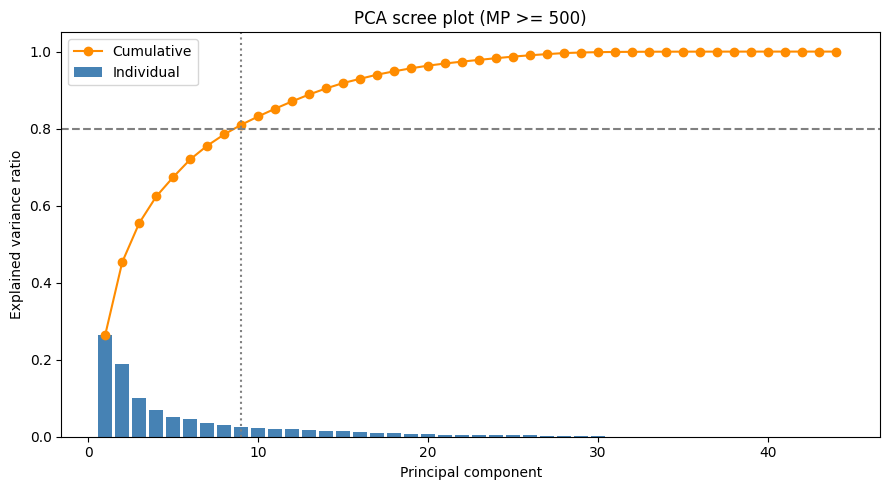

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(range(1, len(explained) + 1), explained, color='steelblue', label='Individual')
ax.plot(range(1, len(cumulative) + 1), cumulative, color='darkorange', marker='o', label='Cumulative')
ax.axhline(0.80, color='gray', linestyle='--')
ax.axvline(n_components, color='gray', linestyle=':')
ax.set_xlabel('Principal component')
ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA scree plot (MP >= 500)')
ax.legend()
plt.tight_layout()
plt.show()


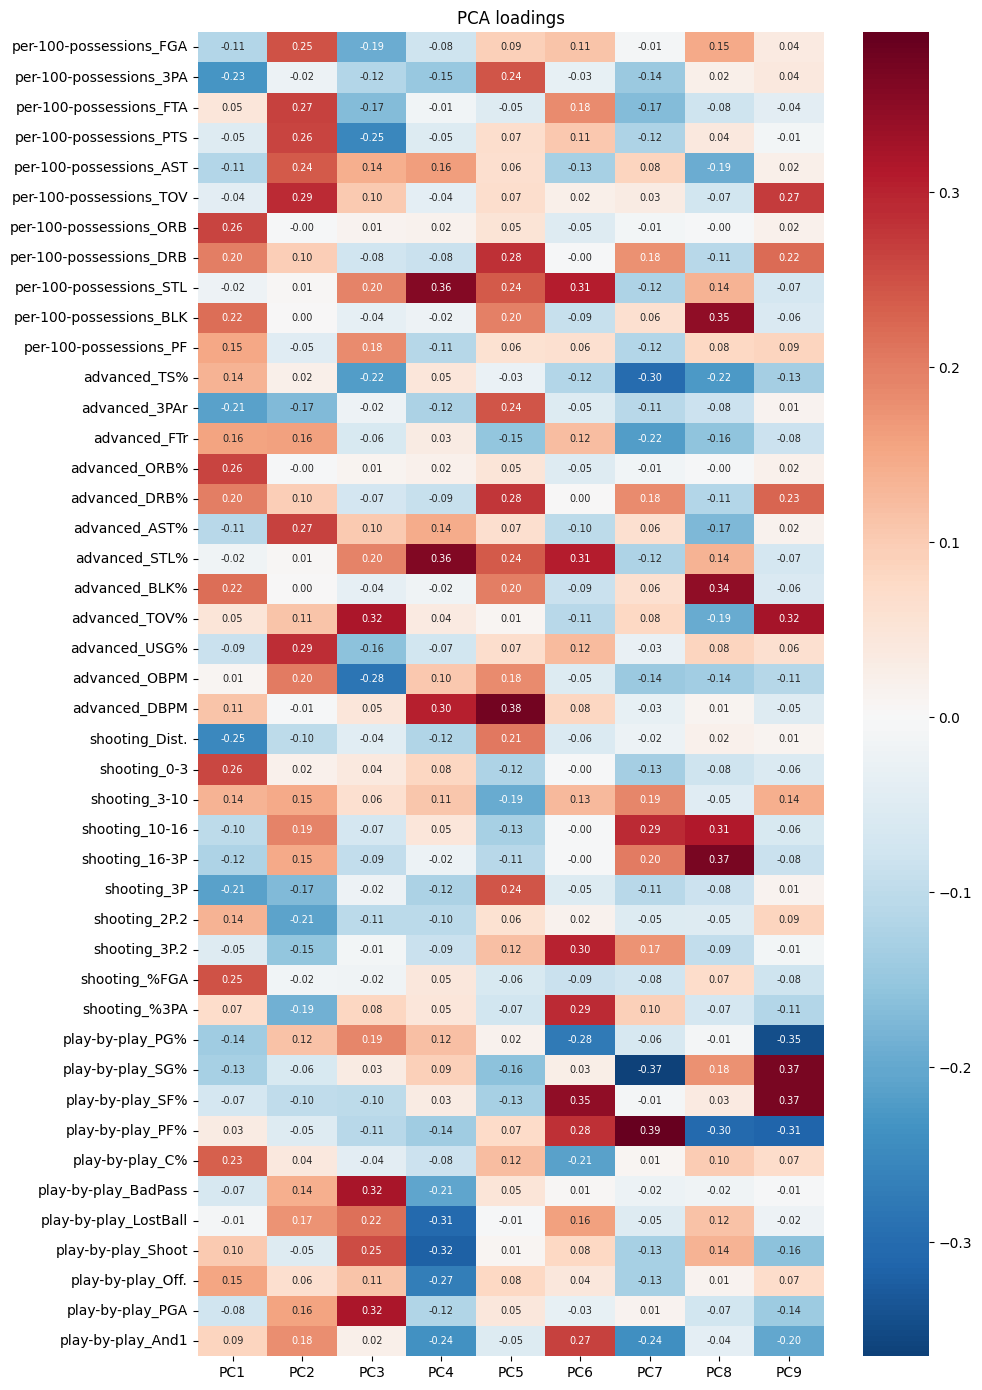

PC1  (-) ['shooting_Dist.', 'per-100-possessions_3PA', 'advanced_3PAr']   (+) ['shooting_0-3', 'per-100-possessions_ORB', 'advanced_ORB%']
PC2  (-) ['shooting_2P.2', 'shooting_%3PA', 'shooting_3P']   (+) ['per-100-possessions_FTA', 'advanced_USG%', 'per-100-possessions_TOV']
PC3  (-) ['advanced_OBPM', 'per-100-possessions_PTS', 'advanced_TS%']   (+) ['advanced_TOV%', 'play-by-play_PGA', 'play-by-play_BadPass']
PC4  (-) ['play-by-play_Shoot', 'play-by-play_LostBall', 'play-by-play_Off.']   (+) ['advanced_DBPM', 'per-100-possessions_STL', 'advanced_STL%']

PC1 (26.5% of total variance)
                         % of PC direction  cumulative %
advanced_ORB%                7.0         +           7.0
per-100-possessions_ORB      6.9         +          13.9
shooting_0-3                 6.7         +          20.6
shooting_Dist.               6.3         -          26.9
shooting_%FGA                6.1         +          33.0
play-by-play_C%              5.5         +          38.5
per-100-po

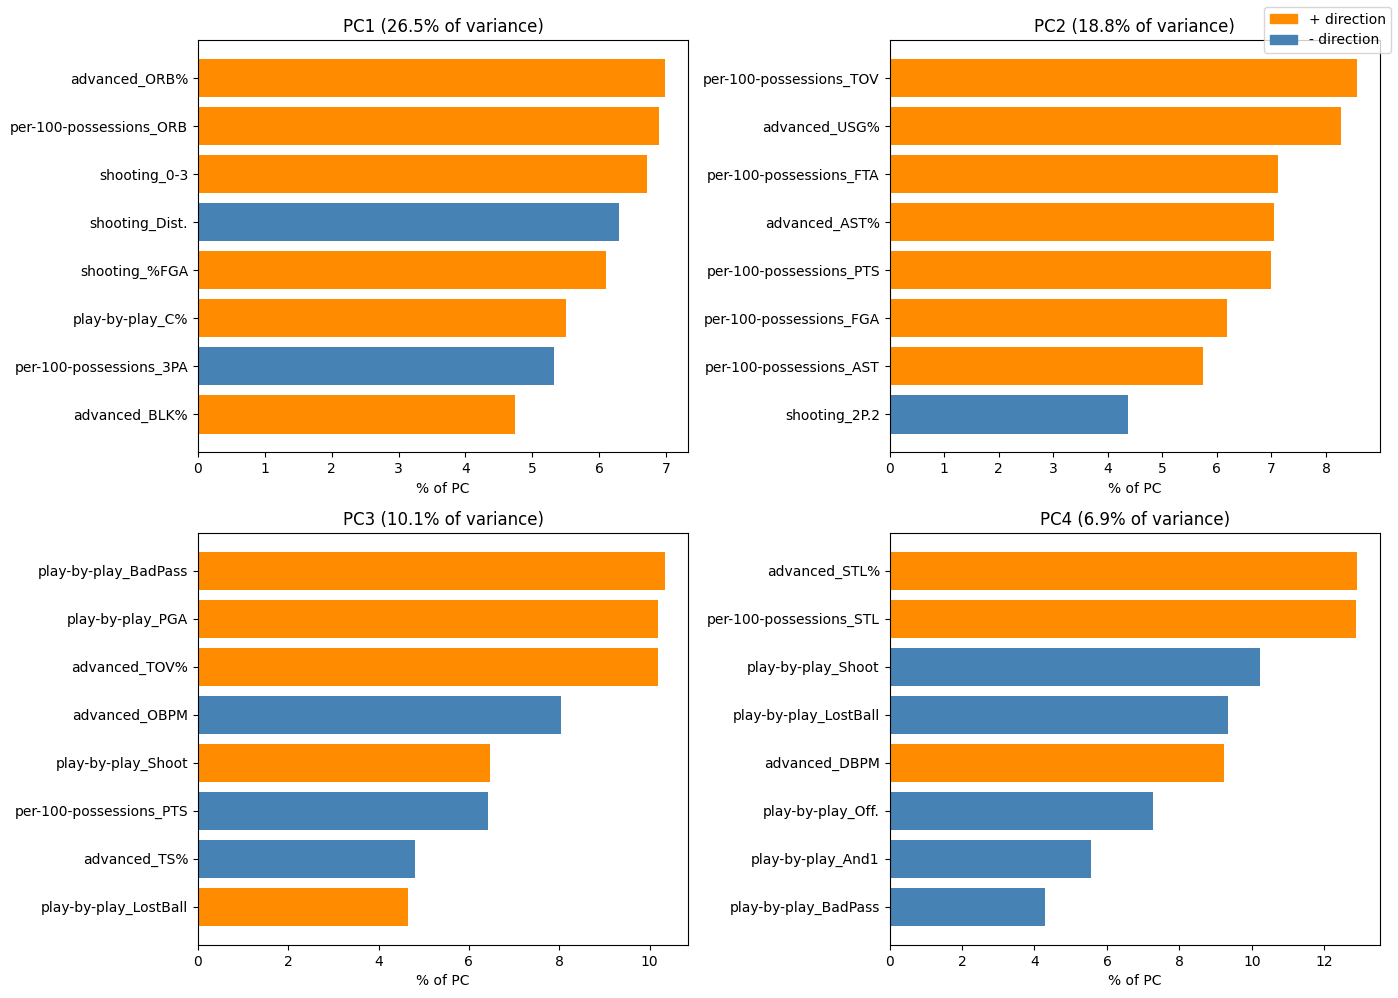

In [26]:
pc_cols = [f'PC{i+1}' for i in range(n_components)]
loadings = pd.DataFrame(pca.components_[:n_components].T, index=features, columns=pc_cols)

plt.figure(figsize=(10, 14))
sns.heatmap(loadings, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('PCA loadings')
plt.tight_layout()
plt.show()

# Top +/- features per component, to help name each axis
for pc in pc_cols[:4]:
    s = loadings[pc].sort_values()
    print(f'{pc}  (-) {list(s.index[:3])}   (+) {list(s.index[-3:])}')

top_n = 8

# PRint contributions to each principal component.
for pc in pc_cols[:4]:
    i = pc_cols.index(pc)
    top = pd.DataFrame({
        '% of PC': contribution[pc],
        'direction': np.where(pca.components_[i] > 0, '+', '-'),
    }).sort_values('% of PC', ascending=False).head(top_n)
    top['cumulative %'] = top['% of PC'].cumsum()

    print(f'\n{pc} ({explained[i]:.1%} of total variance)')
    print(top.round(1).to_string())


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, pc in zip(axes.flat, pc_cols[:4]):
    i = pc_cols.index(pc)
    top = contribution[pc].sort_values(ascending=False).head(top_n)
    signs = np.sign(pd.Series(pca.components_[i], index=features)[top.index])
    ax.barh(top.index, top.values, color=np.where(signs > 0, 'darkorange', 'steelblue'))
    ax.invert_yaxis()  # largest at the top
    ax.set_title(f'{pc} ({explained[i]:.1%} of variance)')
    ax.set_xlabel('% of PC')

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ['darkorange', 'steelblue']]
fig.legend(handles, ['+ direction', '- direction'], loc='upper right')
plt.tight_layout()
plt.show()


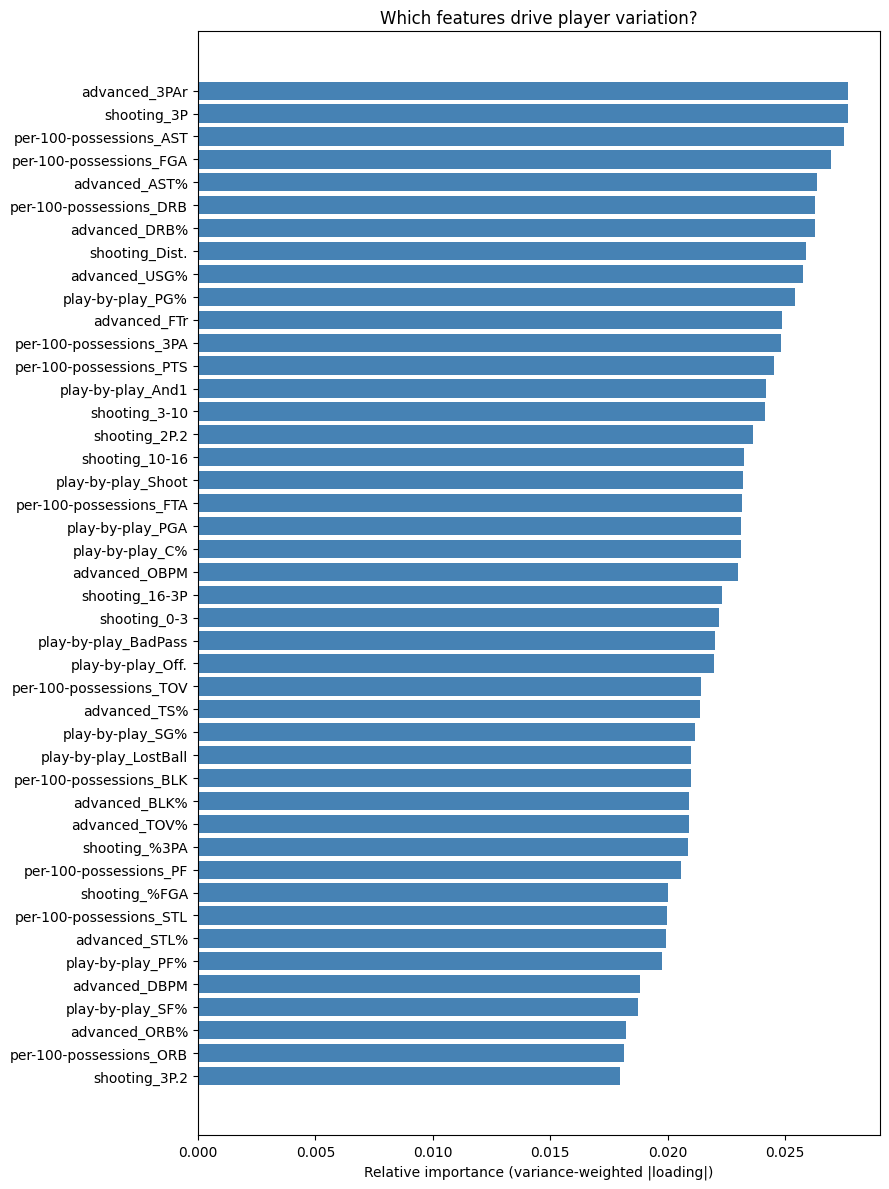

In [ ]:
# |loading| weighted by how much variance each PC explains, summed over the kept PCs
importance = (loadings.abs() * explained[:n_components]).sum(axis=1)
importance = (importance / importance.sum()).sort_values(ascending=False)

plt.figure(figsize=(9, 12))
plt.barh(importance.index, importance.values, color='steelblue')
plt.gca().invert_yaxis()
plt.xlabel('Relative importance (variance-weighted |loading|)')
plt.title('Which features drive player variation?')
plt.tight_layout()
plt.show()


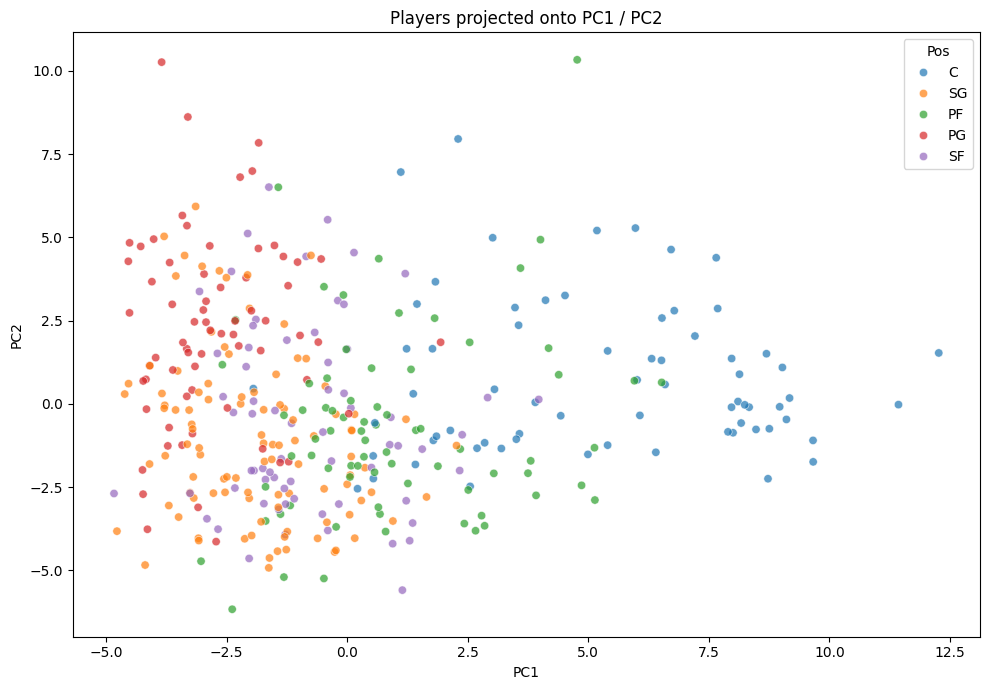

In [23]:
scores = pd.DataFrame(pca.transform(X_scaled)[:, :n_components], columns=pc_cols)
scores['Player'] = df['Player']
scores['Pos'] = df['advanced_Pos']

plt.figure(figsize=(10, 7))
sns.scatterplot(data=scores, x='PC1', y='PC2', hue='Pos', alpha=0.7)
plt.title('Players projected onto PC1 / PC2')
plt.tight_layout()
plt.show()
